# M5 Data Exploration and Data Understanding

**Group 2 - MIA5130A Systems Optimization and Management**

This notebook investigates whether M5 can support a pipeline from demand forecasts
to inventory allocation and delivery planning. It profiles **all five supplied CSV
files**, explains what each record means, explores sales and prices, and creates an
illustrative forecasting dataset for ten products. The final section generates a
report-ready Data Understanding draft directly from the calculated findings.

**Main dataset source:** [M5 Forecasting — Accuracy on Kaggle](https://www.kaggle.com/competitions/m5-forecasting-accuracy/data).
SNAP terminology is explained using [USDA's program overview](https://www.ers.usda.gov/topics/food-nutrition-assistance/supplemental-nutrition-assistance-program-snap).
Counts, dates, and charts in this notebook are calculated from the local CSV files.

The observed sales come from U.S. Walmart stores. Prices are discussed in **U.S.
dollars**, and SNAP is a **U.S.** food assistance program. These details matter for
a Canadian audience and for any later attempt to apply the findings in Canada.

## How to use this notebook

1. Install the dependencies listed in `requirements.txt` in a Python environment.
2. Open this notebook in JupyterLab or a notebook editor and select that environment.
3. Set `DATA_DIR_OVERRIDE` below if the CSV files are not in one of the suggested locations.
4. Run the notebook from top to bottom. The delivered copy already includes executed outputs.

The full sales table contains nearly 60 million daily observations. To limit memory
use, we retain its wide layout for the full audit and reshape only the selected
ten-product subset. Allow roughly 1–2 GB of working memory. The notebook reads the
source files and writes its own tables, charts, and summary under `outputs/`.

## Contents

1. Setup and source files
2. File structure and data dictionary
3. Product and store hierarchy
4. Data quality and joins
5. Sales distributions, trends, and seasonality
6. Events and SNAP
7. Prices and availability
8. Proposed project scope
9. Prediction target, features, and chronological splits
10. Simple validation baselines
11. Inventory and routing implications
12. Data Understanding draft and exports

## 1 Setup and source files

The data directory is configurable. `M5_DATA_DIR` is an optional environment variable;
otherwise the notebook looks for `data/` or a downloaded `m5-forecasting-accuracy/`
folder. No Kaggle credentials or internet connection are needed once the files exist.

In [1]:
from pathlib import Path
import os
import gc
import json
import hashlib
import platform
import tempfile
import importlib.metadata as metadata

os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "m5-matplotlib-cache"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
from IPython.display import display, Markdown

%matplotlib inline

DATA_DIR_OVERRIDE = None  # Example: Path("/path/to/m5-forecasting-accuracy")
PROJECT_DIR = Path.cwd()
OUTPUT_DIR = PROJECT_DIR / "outputs"
FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 14)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160,
                     "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.2, "axes.titleweight": "bold"})
BLUE, TEAL, GOLD, RED = "#265D8C", "#20877D", "#CE9031", "#B64D4D"

required_files = ["calendar.csv", "sales_train_evaluation.csv",
                  "sales_train_validation.csv", "sell_prices.csv", "sample_submission.csv"]
candidates = ([Path(DATA_DIR_OVERRIDE).expanduser()] if DATA_DIR_OVERRIDE else [])
if os.environ.get("M5_DATA_DIR"):
    candidates.append(Path(os.environ["M5_DATA_DIR"]).expanduser())
candidates += [PROJECT_DIR / "data", PROJECT_DIR / "m5-forecasting-accuracy",
               PROJECT_DIR.parent / "m5-forecasting-accuracy",
               Path.home() / "Downloads" / "m5-forecasting-accuracy"]
DATA_DIR = next((p.resolve() for p in candidates if all((p/f).is_file() for f in required_files)), None)
if DATA_DIR is None:
    raise FileNotFoundError("Set DATA_DIR_OVERRIDE to the folder containing all five M5 CSV files.")

def show_table(frame, name=None, index=False):
    display(frame)
    if name:
        frame.to_csv(OUTPUT_DIR / f"{name}.csv", index=index)

def save_figure(fig, name):
    fig.savefig(FIGURE_DIR / f"{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)

versions = {package: metadata.version(package) for package in
            ["numpy", "pandas", "matplotlib", "ipykernel", "nbformat"]}
versions["python"] = platform.python_version()
print("Data folder:", DATA_DIR.name)
print("Analysis outputs: ./outputs/ under the notebook's working directory")
display(pd.Series(versions, name="Executed versions").to_frame())

Data folder: m5-forecasting-accuracy
Analysis outputs: ./outputs/ under the notebook's working directory


,Executed versions
numpy,2.3.5
pandas,2.2.3
matplotlib,3.11.2
ipykernel,7.4.0
nbformat,5.11.1
python,3.12.14


In [2]:
def file_md5(path):
    digest = hashlib.md5()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(8 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

manifest = pd.DataFrame([
    {"file": file, "size_MiB": (DATA_DIR/file).stat().st_size / 1024**2,
     "md5": file_md5(DATA_DIR/file)} for file in required_files
])
source_hashes = dict(zip(manifest.file, manifest.md5))
show_table(manifest, "source_manifest")

,file,size_MiB,md5
0,calendar.csv,0.099,3ffeab2991b0c8e861d008b39ea4c95c
1,sales_train_evaluation.csv,116.097,b806dfc9f30a745102b708c09951f6aa
2,sales_train_validation.csv,114.448,26a366a25beb57b0a8f4c7b148758f94
3,sell_prices.csv,193.973,08c591caa99e55daf3e0ccac913f7c85
4,sample_submission.csv,4.987,c281a69d7c011274899d92020a66e25b


## 2 File structure and data dictionary

- **Sales:** one row per product and store, with one numeric column for each day.
- **Calendar:** one row per date; `d` connects a sales column to its date and week.
- **Prices:** one row per product, store, and retail week.
- **Validation sales:** an earlier, overlapping version of the longer evaluation file.
- **Sample submission:** the competition's output template, not additional observations.

The word *evaluation* in a filename does not define our project's test split. We
create chronological splits explicitly later. We will not append the two sales files.

In [3]:
calendar = pd.read_csv(DATA_DIR / "calendar.csv", parse_dates=["date"])
prices = pd.read_csv(DATA_DIR / "sell_prices.csv", dtype={
    "store_id": "category", "item_id": "category", "wm_yr_wk": "int32", "sell_price": "float64"})
header = pd.read_csv(DATA_DIR / "sales_train_evaluation.csv", nrows=0).columns
day_cols = [c for c in header if c.startswith("d_")]
id_cols = [c for c in header if c not in day_cols]
sales = pd.read_csv(DATA_DIR / "sales_train_evaluation.csv",
                    dtype={**dict.fromkeys(day_cols, "int32"), **dict.fromkeys(id_cols, "category")})
unit_sales = sales[day_cols].to_numpy(copy=False)
historical_calendar = calendar.set_index("d").loc[day_cols].reset_index()
dates = pd.DatetimeIndex(historical_calendar.date)
submission = pd.read_csv(DATA_DIR / "sample_submission.csv")
validation_header = pd.read_csv(DATA_DIR / "sales_train_validation.csv", nrows=0).columns
validation_days = [c for c in validation_header if c.startswith("d_")]

file_structure = pd.DataFrame([
    ["sales_train_evaluation.csv", len(sales), len(sales.columns), "Product–store", str(dates.min().date()), str(dates.max().date())],
    ["sales_train_validation.csv", None, len(validation_header), "Product–store; overlap checked below", "Pending check", "Pending check"],
    ["calendar.csv", len(calendar), len(calendar.columns), "Day", str(calendar.date.min().date()), str(calendar.date.max().date())],
    ["sell_prices.csv", len(prices), len(prices.columns), "Product–store–week", "Join through calendar", "Join through calendar"],
    ["sample_submission.csv", len(submission), len(submission.columns), "Forecast series", "F1", "F28"],
], columns=["file", "rows", "columns", "record_grain", "start", "end"])
file_structure["rows"]=file_structure.rows.astype("Int64")
show_table(file_structure, "file_structure")
display(sales[id_cols + day_cols[:4] + day_cols[-3:]].head(3))
display(calendar.head(3))
display(prices.head(3))

,file,rows,columns,record_grain,start,end
0,sales_train_evaluation.csv,30490,1947,Product–store,2011-01-29,2016-05-22
1,sales_train_validation.csv,<NA>,1919,Product–store; overlap checked below,Pending check,Pending check
2,calendar.csv,1969,14,Day,2011-01-29,2016-06-19
3,sell_prices.csv,6841121,4,Product–store–week,Join through calendar,Join through calendar
4,sample_submission.csv,60980,29,Forecast series,F1,F28


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,d_1939,d_1940,d_1941
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,3,0,1
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,3,0,1


,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0


,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.580
1,CA_1,HOBBIES_1_001,11326,9.580
2,CA_1,HOBBIES_1_001,11327,8.260


In [4]:
dictionary = pd.DataFrame([
    ["Sales", "id", "Identifier", "Product–store series with a competition suffix", "Series key; do not model the suffix"],
    ["Sales / prices", "item_id", "Categorical", "Anonymized product code", "Join key and potential input"],
    ["Sales", "dept_id / cat_id", "Categorical", "Department and category", "Product hierarchy; possible inputs"],
    ["Sales / prices", "store_id", "Categorical", "Anonymized store code", "Join key and potential input"],
    ["Sales", "state_id", "Categorical", "CA, TX, or WI", "Location group; select the relevant SNAP flag"],
    ["Sales", "d_1 … d_1941", "Nonnegative integer", "Observed daily units sold", "Past inputs; future observations construct labels"],
    ["Calendar", "d / date", "Key / date", "Sales-day code and actual date", "Daily join and time ordering"],
    ["Calendar / prices", "wm_yr_wk", "Week key", "Walmart retail week identifier", "Price join; not an ordinary ISO week number"],
    ["Calendar", "weekday / wday / month / year", "Calendar fields", "Day and seasonal context", "Known calendar inputs"],
    ["Calendar", "event_name_1/2 / event_type_1/2", "Categorical; optional", "Up to two listed events per date", "Known calendar inputs; blanks often mean no event"],
    ["Calendar", "snap_CA / snap_TX / snap_WI", "Binary 0/1", "SNAP purchasing-day indicators by state", "Use the store's matching state flag"],
    ["Prices", "sell_price", "Positive numeric; USD", "Weekly average selling price for a product and store", "Historical or planned-price input; revenue assumption"],
    ["Submission", "F1 … F28", "Forecast placeholders", "Competition's 28 forecast positions", "Not observed demand or model inputs"],
], columns=["table", "field", "type", "meaning", "role_in_project"])
show_table(dictionary, "data_dictionary")

,table,field,type,meaning,role_in_project
0,Sales,id,Identifier,Product–store series with a competition suffix,Series key; do not model the suffix
1,Sales / prices,item_id,Categorical,Anonymized product code,Join key and potential input
2,Sales,dept_id / cat_id,Categorical,Department and category,Product hierarchy; possible inputs
3,Sales / prices,store_id,Categorical,Anonymized store code,Join key and potential input
4,Sales,state_id,Categorical,"CA, TX, or WI",Location group; select the relevant SNAP flag
5,Sales,d_1 … d_1941,Nonnegative integer,Observed daily units sold,Past inputs; future observations construct labels
6,Calendar,d / date,Key / date,Sales-day code and actual date,Daily join and time ordering
7,Calendar / prices,wm_yr_wk,Week key,Walmart retail week identifier,Price join; not an ordinary ISO week number
8,Calendar,weekday / wday / month / year,Calendar fields,Day and seasonal context,Known calendar inputs
9,Calendar,event_name_1/2 / event_type_1/2,Categorical; optional,Up to two listed events per date,Known calendar inputs; blanks often mean no event


### Verify the overlapping sales files

We compare **every overlapping daily sales value**, in chunks, and check all
product and location identifiers. Removing the `_validation` and `_evaluation`
suffixes from `id` should leave the same series keys. This avoids loading both
large sales tables into memory at once.

In [5]:
offset = 0
same_sales, same_keys, same_metadata = True, True, True
validation_nulls = 0
validation_dtypes = {**dict.fromkeys(validation_days, "int32"), **dict.fromkeys(id_cols, "category")}
for chunk in pd.read_csv(DATA_DIR / "sales_train_validation.csv", dtype=validation_dtypes, chunksize=2000):
    reference = sales.iloc[offset:offset + len(chunk)]
    same_sales &= np.array_equal(chunk[validation_days].to_numpy(), reference[validation_days].to_numpy())
    same_keys &= np.array_equal(chunk.id.astype(str).str.removesuffix("_validation").to_numpy(),
                                reference.id.astype(str).str.removesuffix("_evaluation").to_numpy())
    same_metadata &= np.array_equal(chunk[id_cols[1:]].astype(str).to_numpy(),
                                    reference[id_cols[1:]].astype(str).to_numpy())
    validation_nulls += int(chunk.isna().sum().sum())
    offset += len(chunk)
assert offset == len(sales) and same_sales and same_keys and same_metadata
validation_last_date = calendar.set_index("d").loc[validation_days[-1], "date"]
mask = file_structure.file.eq("sales_train_validation.csv")
file_structure.loc[mask, ["rows", "start", "end"]] = [offset, str(dates.min().date()), str(validation_last_date.date())]
show_table(file_structure, "file_structure")
display(Markdown(f"**Result:** all {offset:,} series match across {len(validation_days):,} overlapping days. "
                 f"The longer file adds {len(day_cols)-len(validation_days)} observed days. We use it once, without concatenation."))
del chunk, reference
gc.collect()

,file,rows,columns,record_grain,start,end
0,sales_train_evaluation.csv,30490,1947,Product–store,2011-01-29,2016-05-22
1,sales_train_validation.csv,30490,1919,Product–store; overlap checked below,2011-01-29,2016-04-24
2,calendar.csv,1969,14,Day,2011-01-29,2016-06-19
3,sell_prices.csv,6841121,4,Product–store–week,Join through calendar,Join through calendar
4,sample_submission.csv,60980,29,Forecast series,F1,F28


**Result:** all 30,490 series match across 1,913 overlapping days. The longer file adds 28 observed days. We use it once, without concatenation.

32

## 3 Product and store hierarchy

Identifiers let us group demand by product, department, category, store, or state.
They do not identify exact products or street addresses. Category and store totals
below use **unit sales**, so they should not be interpreted as revenue or profit.

,level,count
0,Products,3049
1,Departments,7
2,Categories,3
3,Stores,10
4,States,3
5,Product–store series,30490


,cat_id,product_store_series,products,total_units
0,HOBBIES,5650,565,6240656
1,HOUSEHOLD,10470,1047,14764090
2,FOODS,14370,1437,45922427


,state_id,store_id,product_store_series,total_units
0,CA,CA_1,3049,7832248
1,CA,CA_2,3049,5818395
2,CA,CA_3,3049,11363540
3,CA,CA_4,3049,4182534
4,TX,TX_1,3049,5692823
5,TX,TX_2,3049,7329642
6,TX,TX_3,3049,6205940
7,WI,WI_1,3049,5261506
8,WI,WI_2,3049,6697988
9,WI,WI_3,3049,6542557


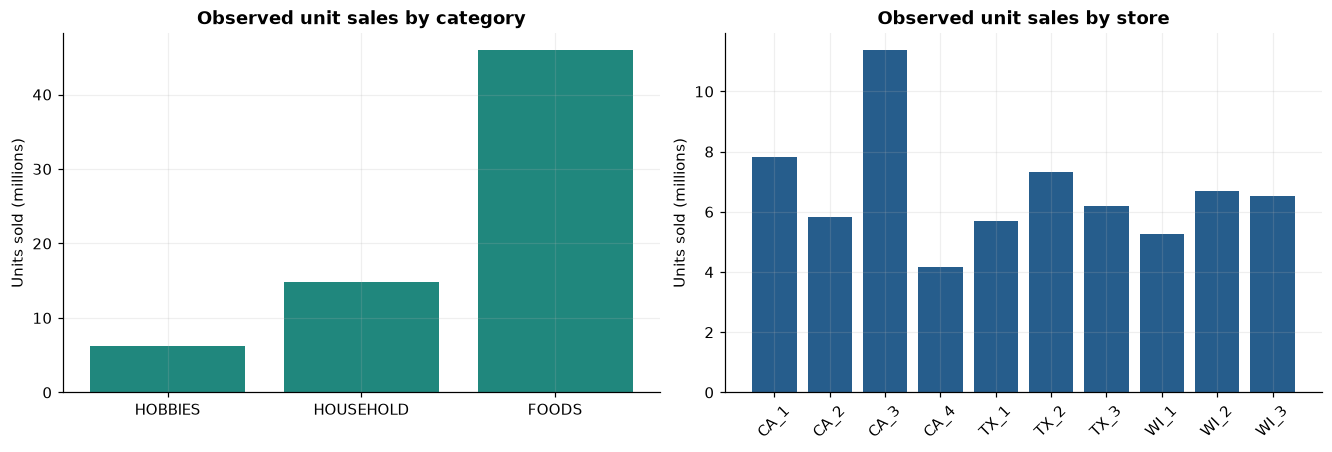

In [6]:
hierarchy = pd.DataFrame({"level": ["Products", "Departments", "Categories", "Stores", "States", "Product–store series"],
                          "count": [sales[c].nunique() for c in ["item_id", "dept_id", "cat_id", "store_id", "state_id", "id"]]})
show_table(hierarchy, "hierarchy")
series_totals = sales[id_cols].copy()
series_totals["total_units"] = unit_sales.sum(axis=1, dtype=np.int64)
series_totals["zero_fraction"] = np.count_nonzero(unit_sales == 0, axis=1) / len(day_cols)
category_totals = series_totals.groupby("cat_id", observed=True).agg(
    product_store_series=("id", "size"), products=("item_id", "nunique"), total_units=("total_units", "sum")).reset_index()
store_totals = series_totals.groupby(["state_id", "store_id"], observed=True).agg(
    product_store_series=("id", "size"), total_units=("total_units", "sum")).reset_index()
show_table(category_totals, "category_totals")
show_table(store_totals, "store_totals")
fig, ax = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
ax[0].bar(category_totals.cat_id.astype(str), category_totals.total_units / 1e6, color=TEAL)
ax[0].set(title="Observed unit sales by category", ylabel="Units sold (millions)")
ax[1].bar(store_totals.store_id.astype(str), store_totals.total_units / 1e6, color=BLUE)
ax[1].tick_params(axis="x", rotation=45)
ax[1].set(title="Observed unit sales by store", ylabel="Units sold (millions)")
save_figure(fig, "01_category_and_store_sales")

## 4 Data quality and joins

We check null values, key uniqueness, valid sales and prices, dates, and identifier
relationships. Missing optional event names are distinguished from missing measurements.
After these checks we audit the full sales-to-price join without expanding all daily rows.

In [7]:
null_records = []
for name, frame in [("sales_train_evaluation", sales), ("calendar", calendar), ("sell_prices", prices), ("sample_submission", submission)]:
    for column, count in frame.isna().sum().items():
        if count:
            null_records.append({"table": name, "field": column, "nulls": int(count), "fraction": count/len(frame)})
null_summary = pd.DataFrame(null_records, columns=["table", "field", "nulls", "fraction"])
show_table(null_summary, "missing_cell_summary")

sales_nulls = int(sales.isna().sum().sum())
negative_sales = int(np.count_nonzero(unit_sales < 0))
sales_duplicates = int(sales.duplicated(["item_id", "store_id"]).sum())
price_duplicates = int(prices.duplicated(["item_id", "store_id", "wm_yr_wk"]).sum())
consecutive_dates = bool(calendar.date.diff().dropna().eq(pd.Timedelta(days=1)).all())
quality = pd.DataFrame([
    ["Sales missing cells", sales_nulls, sales_nulls == 0],
    ["Sales negative unit counts", negative_sales, negative_sales == 0],
    ["Duplicate sales product–store keys", sales_duplicates, sales_duplicates == 0],
    ["Duplicate sales id values", int(sales.id.duplicated().sum()), not sales.id.duplicated().any()],
    ["Duplicate calendar d keys", int(calendar.d.duplicated().sum()), not calendar.d.duplicated().any()],
    ["Duplicate calendar dates", int(calendar.date.duplicated().sum()), not calendar.date.duplicated().any()],
    ["Calendar dates consecutive", consecutive_dates, consecutive_dates],
    ["Historical days absent from calendar", len(set(day_cols)-set(calendar.d)), set(day_cols).issubset(set(calendar.d))],
    ["Duplicate product–store–week price keys", price_duplicates, price_duplicates == 0],
    ["Price missing cells", int(prices.isna().sum().sum()), not prices.isna().any().any()],
    ["Nonpositive listed prices", int(prices.sell_price.le(0).sum()), prices.sell_price.gt(0).all()],
    ["SNAP values restricted to 0 and 1", True, all(set(calendar[c].unique()) <= {0,1} for c in ["snap_CA","snap_TX","snap_WI"])],
    ["Product has one department and category", True, sales.groupby("item_id", observed=True)[["dept_id","cat_id"]].nunique().le(1).all().all()],
    ["Store belongs to one state", True, sales.groupby("store_id", observed=True).state_id.nunique().eq(1).all()],
    ["Validation overlaps exactly", same_sales, same_sales and same_keys and same_metadata],
], columns=["check", "observed", "passed"])
show_table(quality, "quality_checks")
assert quality.passed.all(), "Inspect the quality table before continuing."
assert np.issubdtype(unit_sales.dtype, np.integer)
display(Markdown("**Interpretation:** optional calendar event fields explain the null cells shown above. "
                 "A file can have no missing price cells and still have absent price records after a join. "
                 "We check that distinction next. Large valid sales values are not automatically removed as outliers."))

,table,field,nulls,fraction
0,calendar,event_name_1,1807,0.918
1,calendar,event_type_1,1807,0.918
2,calendar,event_name_2,1964,0.997
3,calendar,event_type_2,1964,0.997


,check,observed,passed
0,Sales missing cells,0,True
1,Sales negative unit counts,0,True
2,Duplicate sales product–store keys,0,True
3,Duplicate sales id values,0,True
4,Duplicate calendar d keys,0,True
5,Duplicate calendar dates,0,True
6,Calendar dates consecutive,True,True
7,Historical days absent from calendar,0,True
8,Duplicate product–store–week price keys,0,True
9,Price missing cells,0,True


**Interpretation:** optional calendar event fields explain the null cells shown above. A file can have no missing price cells and still have absent price records after a join. We check that distinction next. Large valid sales values are not automatically removed as outliers.

In [8]:
keys = pd.MultiIndex.from_frame(sales[["store_id", "item_id"]])
price_wide = prices.set_index(["store_id", "item_id", "wm_yr_wk"]).sell_price.unstack("wm_yr_wk").reindex(keys)
first_price_week = prices.groupby(["store_id","item_id"], observed=True).wm_yr_wk.min().reindex(keys).to_numpy()
day_weeks = historical_calendar.wm_yr_wk.to_numpy()
missing_price_days = 0
positive_without_price = 0
missing_before_first_price = 0
daily_price_missing = np.zeros(len(day_cols), dtype=np.int64)
for week in pd.unique(day_weeks):
    positions = np.flatnonzero(day_weeks == week)
    missing = price_wide[week].isna().to_numpy()
    daily_price_missing[positions] = int(missing.sum())
    missing_price_days += int(missing.sum()) * len(positions)
    positive_without_price += int(np.count_nonzero(unit_sales[np.ix_(missing, positions)] > 0))
    missing_before_first_price += int(np.count_nonzero(missing & (first_price_week > week))) * len(positions)

zero_count = int(np.count_nonzero(unit_sales == 0))
observation_count = int(unit_sales.size)
zero_fraction = zero_count / observation_count
missing_price_fraction = missing_price_days / observation_count
priced_zero_count = zero_count - missing_price_days
priced_zero_fraction = priced_zero_count / (observation_count-missing_price_days)
assert positive_without_price == 0, "Positive sales without a listed price need investigation."
price_join_audit = pd.DataFrame([
    ["All historical product–store-days", observation_count],
    ["Days without a matching weekly price", missing_price_days],
    ["Of those, before the first recorded price week", missing_before_first_price],
    ["Of those, after or within recorded price history", missing_price_days-missing_before_first_price],
    ["Positive sales observations without a price", positive_without_price],
    ["Zero sales observations with a price", priced_zero_count],
], columns=["measure", "count"])
show_table(price_join_audit, "price_join_audit")
display(Markdown(f"**Finding:** {missing_price_fraction:.1%} of historical product–store-days have no matching price record. "
                 f"All of them have zero sales. Overall zero sales are {zero_fraction:.1%}; "
                 f"within days with a listed price, the zero-sales share is {priced_zero_fraction:.1%}. "
                 "This distinguishes selling-history coverage from sparse sales. It does not reveal actual shelf availability or stockouts."))
if missing_before_first_price==missing_price_days:
    display(Markdown("In these supplied files, **every unmatched price record occurs before that series' first recorded price week**. "
                     "This is evidence of different selling-history start dates, rather than random gaps inside the listed-price history."))

,measure,count
0,All historical product–store-days,59181090
1,Days without a matching weekly price,12299413
2,"Of those, before the first recorded price week",12299413
3,"Of those, after or within recorded price history",0
4,Positive sales observations without a price,0
5,Zero sales observations with a price,27942406


**Finding:** 20.8% of historical product–store-days have no matching price record. All of them have zero sales. Overall zero sales are 68.0%; within days with a listed price, the zero-sales share is 59.6%. This distinguishes selling-history coverage from sparse sales. It does not reveal actual shelf availability or stockouts.

In these supplied files, **every unmatched price record occurs before that series' first recorded price week**. This is evidence of different selling-history start dates, rather than random gaps inside the listed-price history.

## 5 Sales distributions, trends, and seasonality

Zero sales are observed values, not missing measurements. Some occur before the
first listed selling price. Zeros during listed-price periods can reflect many
causes; M5 does not identify the cause of each zero. Peaks and long tails also
require examination rather than automatic deletion.

,measure,value
0,Daily observations,59181090
1,Zero observations,40241819
2,Positive observations,18939271
3,Daily minimum,0
4,Daily maximum,763
5,Total units sold,66927173


,quantile,positive_daily_units
0,0.500,2.000
1,0.900,7.000
2,0.950,11.000
3,0.990,28.000
4,0.999,72.000


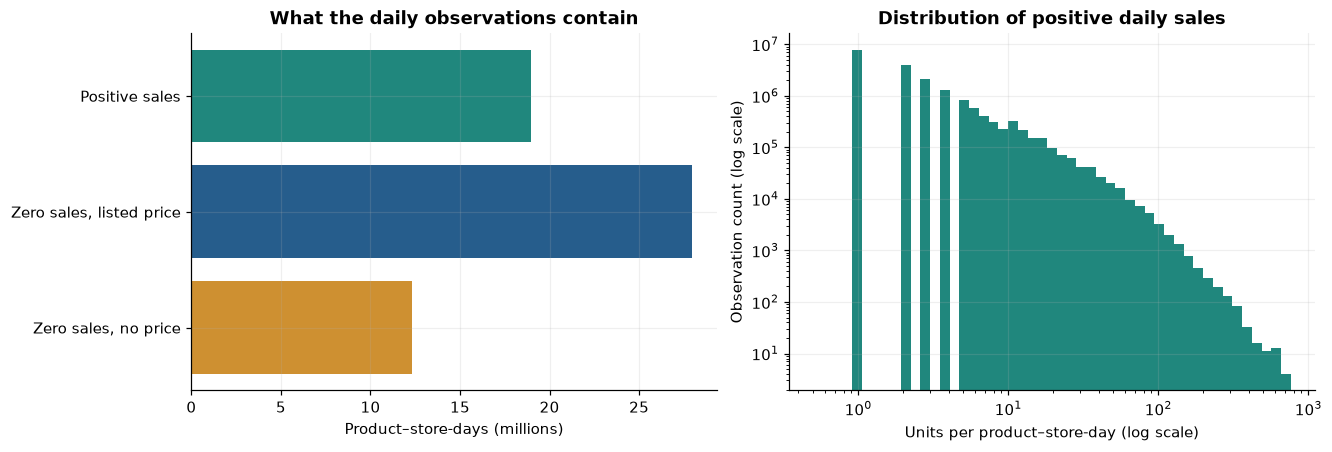

2872

In [9]:
sales_distribution = pd.DataFrame({
    "measure": ["Daily observations", "Zero observations", "Positive observations", "Daily minimum", "Daily maximum", "Total units sold"],
    "value": [observation_count, zero_count, observation_count-zero_count, int(unit_sales.min()), int(unit_sales.max()), int(unit_sales.sum(dtype=np.int64))]})
show_table(sales_distribution, "sales_distribution")
positive_values = unit_sales[unit_sales > 0]
positive_quantiles = pd.DataFrame({"quantile": [0.5,0.9,0.95,0.99,0.999],
                                  "positive_daily_units": np.quantile(positive_values, [0.5,0.9,0.95,0.99,0.999])})
show_table(positive_quantiles, "positive_sales_quantiles")
fig, ax = plt.subplots(1,2,figsize=(12,4),layout="constrained")
counts = [missing_price_days, priced_zero_count, observation_count-zero_count]
ax[0].barh(["Zero sales, no price", "Zero sales, listed price", "Positive sales"], np.array(counts)/1e6,
           color=[GOLD,BLUE,TEAL])
ax[0].set(title="What the daily observations contain", xlabel="Product–store-days (millions)")
bins=np.geomspace(0.5, int(positive_values.max())+0.5, 50)
ax[1].hist(positive_values, bins=bins, color=TEAL)
ax[1].set(xscale="log", yscale="log", title="Distribution of positive daily sales", xlabel="Units per product–store-day (log scale)", ylabel="Observation count (log scale)")
save_figure(fig,"02_sales_distribution")
del positive_values
gc.collect()

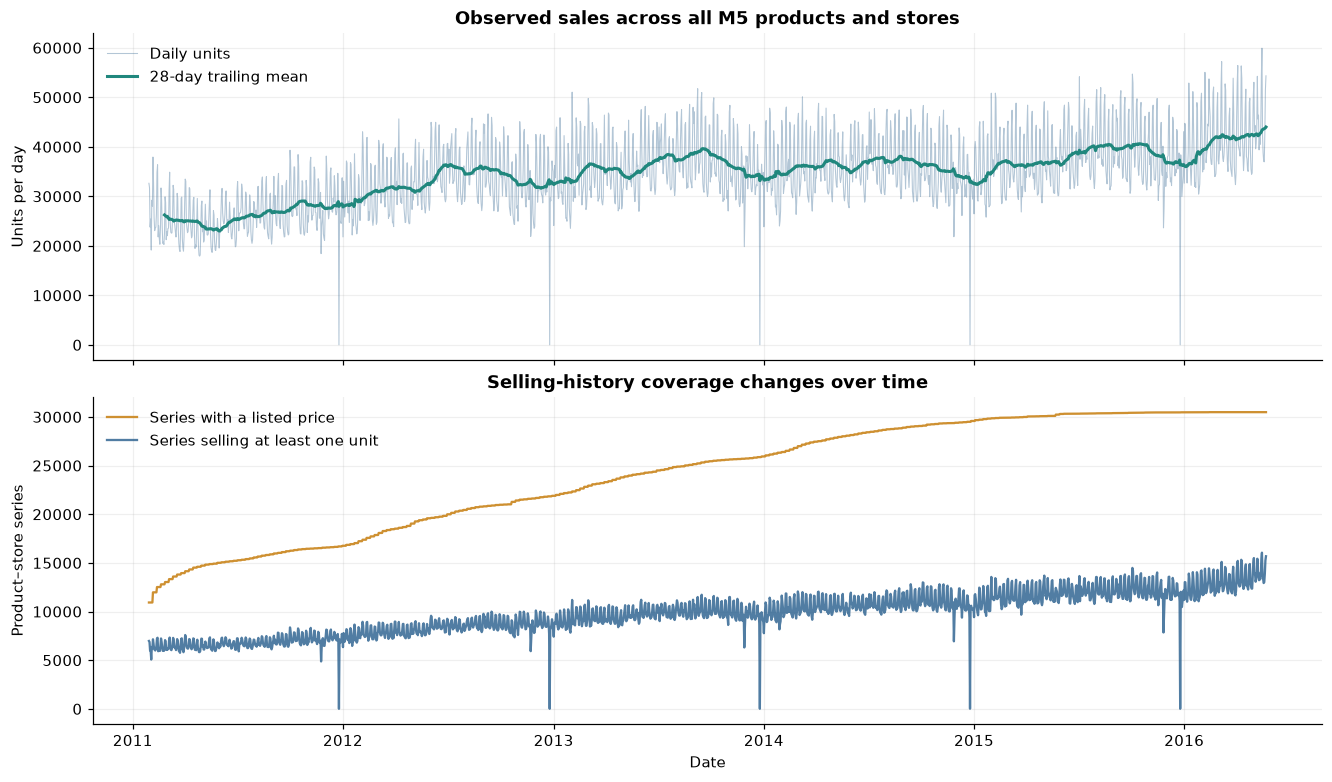

**Interpretation:** changes in aggregate sales can combine demand changes with changes in the number of products being sold. A listed price is only a coverage proxy; it does not prove an item was in stock.

,date,weekday,event_name_1,event_name_2,priced_series


The table highlights dates when **all series record zero sales**. Compare them with the listed calendar events. These are observed zero values on present dates, not absent rows. A holiday or closure explanation needs operational context; the dataset does not contain a store-opening indicator.

In [10]:
daily = historical_calendar.copy()
daily["units"] = unit_sales.sum(axis=0, dtype=np.int64)
daily["priced_series"] = len(sales)-daily_price_missing
daily["series_with_positive_sales"] = np.count_nonzero(unit_sales > 0, axis=0)
category_daily = sales.groupby("cat_id", observed=True)[day_cols].sum().T
category_daily.index = dates
store_daily = sales.groupby("store_id", observed=True)[day_cols].sum().T
store_daily.index = dates
daily["year"] = daily.date.dt.year
daily.to_csv(OUTPUT_DIR/"daily_totals.csv",index=False)
fig, ax=plt.subplots(2,1,figsize=(12,7),sharex=True,layout="constrained")
ax[0].plot(daily.date,daily.units,color=BLUE,alpha=0.35,lw=0.7,label="Daily units")
ax[0].plot(daily.date,daily.units.rolling(28,min_periods=28).mean(),color=TEAL,lw=2,label="28-day trailing mean")
ax[0].set(title="Observed sales across all M5 products and stores",ylabel="Units per day")
ax[0].legend(frameon=False)
ax[1].plot(daily.date,daily.priced_series,color=GOLD,label="Series with a listed price")
ax[1].plot(daily.date,daily.series_with_positive_sales,color=BLUE,alpha=0.8,label="Series selling at least one unit")
ax[1].set(title="Selling-history coverage changes over time",ylabel="Product–store series",xlabel="Date")
ax[1].legend(frameon=False)
save_figure(fig,"03_total_sales_and_coverage")
display(Markdown("**Interpretation:** changes in aggregate sales can combine demand changes with changes in the number of products being sold. "
                 "A listed price is only a coverage proxy; it does not prove an item was in stock."))
zero_sales_dates=daily.loc[daily.units.eq(0),["date","weekday","event_name_1","event_name_2","priced_series"]]
show_table(zero_sales_dates,"dates_with_zero_total_sales")
display(Markdown("The table highlights dates when **all series record zero sales**. Compare them with the listed calendar events. "
                 "These are observed zero values on present dates, not absent rows. A holiday or closure explanation needs operational context; "
                 "the dataset does not contain a store-opening indicator."))

,weekday,mean,median,count
0,Monday,"32,994.931","33,451.000",277
1,Tuesday,"30,500.484","30,901.000",277
2,Wednesday,"30,130.419","31,018.000",277
3,Thursday,"30,321.040","30,757.000",277
4,Friday,"34,357.473","34,864.000",277
5,Saturday,"41,706.270","42,488.000",278
6,Sunday,"41,304.050","42,647.500",278


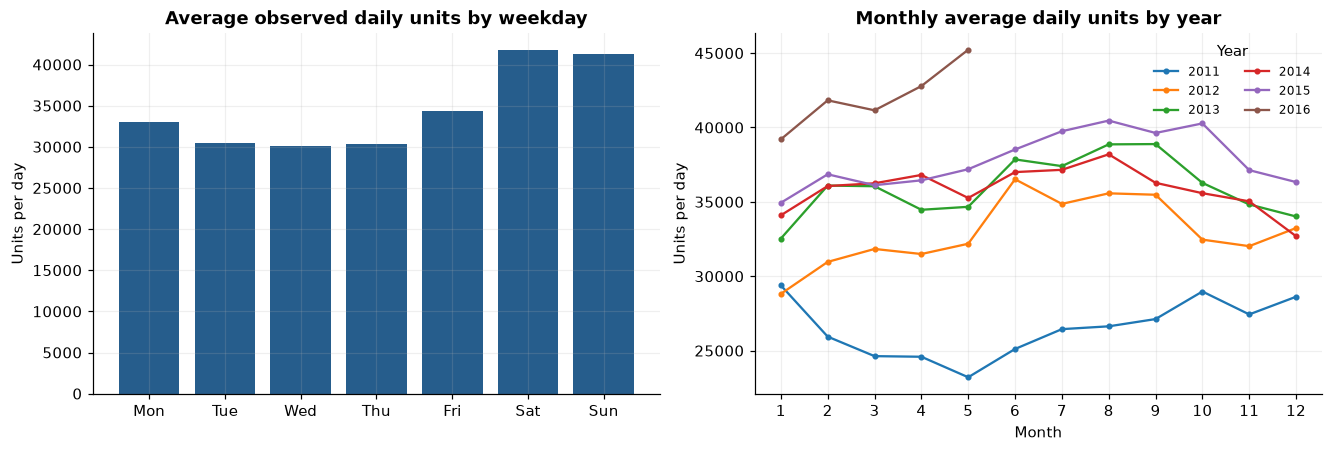

**Interpretation:** these are descriptive averages. The first and last years are incomplete, and product coverage changes across years. Calendar associations should be tested on chronological validation data.

In [11]:
weekday_order=["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
weekday_summary=daily.groupby("weekday").units.agg(["mean","median","count"]).reindex(weekday_order).reset_index()
monthly=daily.groupby([daily.date.dt.year.rename("year"),daily.date.dt.month.rename("month")]).units.mean().unstack("year")
show_table(weekday_summary,"weekday_sales")
monthly.to_csv(OUTPUT_DIR/"monthly_mean_daily_sales.csv")
fig,ax=plt.subplots(1,2,figsize=(12,4),layout="constrained")
ax[0].bar(weekday_summary.weekday.str[:3],weekday_summary["mean"],color=BLUE)
ax[0].set(title="Average observed daily units by weekday",ylabel="Units per day")
for year in monthly:
    ax[1].plot(monthly.index,monthly[year],marker="o",ms=3,label=str(year))
ax[1].set(title="Monthly average daily units by year",xlabel="Month",ylabel="Units per day",xticks=range(1,13))
ax[1].legend(title="Year",frameon=False,ncols=2,fontsize=8)
save_figure(fig,"04_sales_seasonality")
display(Markdown("**Interpretation:** these are descriptive averages. The first and last years are incomplete, "
                 "and product coverage changes across years. Calendar associations should be tested on chronological validation data."))

## 6 Events and SNAP

**SNAP means Supplemental Nutrition Assistance Program.** It is a U.S. government
program that helps eligible low-income households buy food. It appears here because
the dataset contains U.S. retail sales, even though our course team is in Canada.
See [USDA's explanation](https://www.ers.usda.gov/topics/food-nutrition-assistance/supplemental-nutrition-assistance-program-snap).

M5 supplies `snap_CA`, `snap_TX`, and `snap_WI` in `calendar.csv`.
**1** marks a SNAP purchasing day in that state's M5 calendar; **0** is unflagged.
The field does not identify a customer's payment method, actual SNAP spending,
or an individual's eligibility. Use the flag for the store's own state.

The comparisons below are observational associations. Weekday, month, promotions,
store mix, and other factors can influence the averages; they do not measure a
causal SNAP or event effect.

,state,SNAP_flag,days,mean_daily_food_units
0,CA,0,1301,"9,735.971"
1,CA,1,640,"10,733.383"
2,TX,0,1301,"6,453.660"
3,TX,1,640,"7,462.334"
4,WI,0,1301,"6,196.149"
5,WI,1,640,"8,051.981"


,primary_event_type,mean,count
0,National,"29,458.510",51
1,Religious,"34,426.241",54
2,No primary event,"34,609.337",1783
3,Cultural,"34,718.595",37
4,Sporting,"35,796.062",16


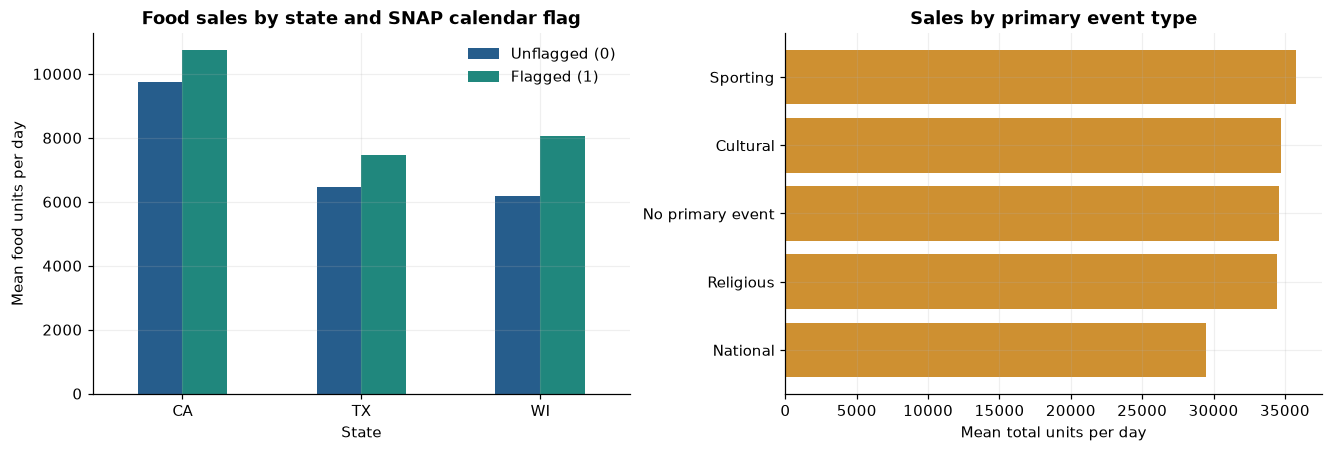

Event comparisons use the **first** listed event type only. Both event slots remain available for feature engineering. These comparisons suggest candidate inputs to validate; they do not establish causation.

In [12]:
food_rows=sales.cat_id.eq("FOODS").to_numpy()
snap_records=[]
for state in sorted(sales.state_id.unique()):
    row_mask=food_rows & sales.state_id.eq(state).to_numpy()
    state_daily=unit_sales[row_mask].sum(axis=0,dtype=np.int64)
    flag=historical_calendar[f"snap_{state}"].to_numpy()
    for value in [0,1]:
        values=state_daily[flag==value]
        snap_records.append({"state":str(state),"SNAP_flag":value,"days":len(values),"mean_daily_food_units":float(values.mean())})
snap_summary=pd.DataFrame(snap_records)
show_table(snap_summary,"snap_food_sales_association")
event_daily=daily.assign(primary_event_type=daily.event_type_1.fillna("No primary event"))
event_summary=event_daily.groupby("primary_event_type").units.agg(["mean","count"]).sort_values("mean").reset_index()
show_table(event_summary,"primary_event_sales_association")
fig,ax=plt.subplots(1,2,figsize=(12,4),layout="constrained")
snap_plot=snap_summary.pivot(index="state",columns="SNAP_flag",values="mean_daily_food_units")
snap_plot.plot.bar(ax=ax[0],color=[BLUE,TEAL],rot=0)
ax[0].set(title="Food sales by state and SNAP calendar flag",xlabel="State",ylabel="Mean food units per day")
ax[0].legend(["Unflagged (0)","Flagged (1)"],frameon=False)
ax[1].barh(event_summary.primary_event_type,event_summary["mean"],color=GOLD)
ax[1].set(title="Sales by primary event type",xlabel="Mean total units per day")
save_figure(fig,"05_calendar_associations")
display(Markdown("Event comparisons use the **first** listed event type only. Both event slots remain available for feature engineering. "
                 "These comparisons suggest candidate inputs to validate; they do not establish causation."))

## 7 Prices and availability

`sell_price` is a weekly selling price, not a purchasing cost or profit margin.
The retail-week key `wm_yr_wk` is used for joins; our proposed weekly forecasting
target later uses Monday–Sunday weeks. Keeping these two definitions separate avoids
incorrect price merges. A missing price record must not be replaced by a zero price.

The example price and sales chart is descriptive. Co-movement does not identify
price elasticity: promotions, availability, seasonality, and demand can change together.

,measure,USD
0,count,"6,841,121.000"
1,mean,4.411
2,std,3.409
3,min,0.010
4,1%,0.480
5,25%,2.180
6,50%,3.470
7,75%,5.840
8,99%,17.920
9,max,107.320


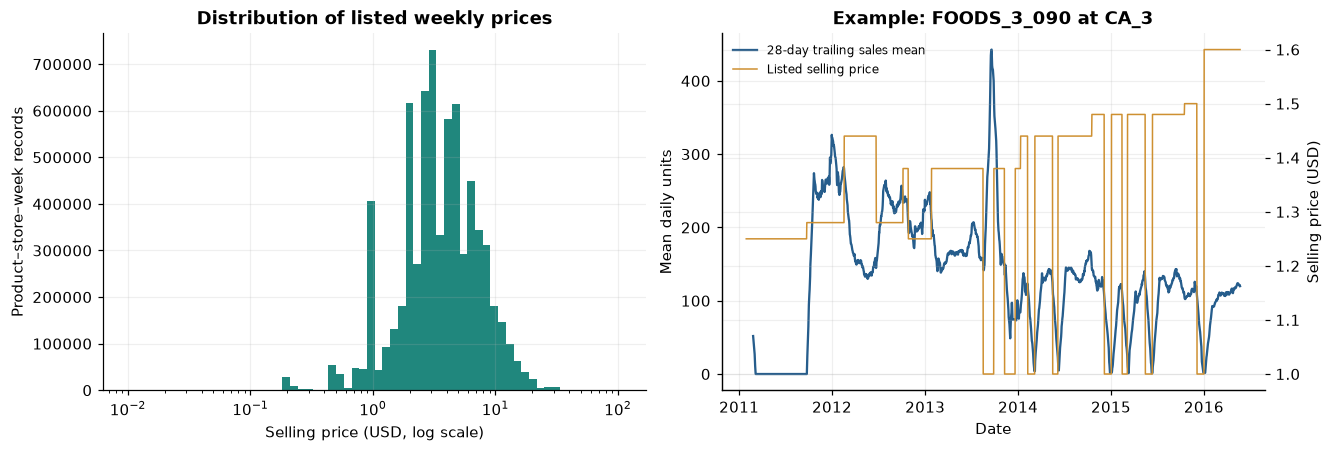

,year,observed_days,priced_series_mean,mean_price_coverage_fraction
0,2011,337,"15,157.359",0.497
1,2012,366,"19,741.962",0.647
2,2013,365,"24,299.534",0.797
3,2014,365,"28,189.808",0.925
4,2015,365,"30,218.964",0.991
5,2016,143,"30,486.413",1.000


In [13]:
price_summary = prices.sell_price.describe(percentiles=[0.01,0.25,0.5,0.75,0.99]).rename_axis("measure").reset_index(name="USD")
show_table(price_summary,"listed_price_summary")
example_position = int(np.argmax(series_totals.total_units.to_numpy()))
example_item = str(sales.iloc[example_position].item_id)
example_store = str(sales.iloc[example_position].store_id)
example_price = prices[(prices.item_id == example_item) & (prices.store_id == example_store)].set_index("wm_yr_wk").sell_price
example_daily = pd.DataFrame({"date":dates,"units":unit_sales[example_position],
                              "sell_price":historical_calendar.wm_yr_wk.map(example_price).to_numpy()})
fig,ax=plt.subplots(1,2,figsize=(12,4),layout="constrained")
price_bins=np.geomspace(prices.sell_price.min(), prices.sell_price.max()*1.001,65)
ax[0].hist(prices.sell_price,bins=price_bins,color=TEAL)
ax[0].set(xscale="log",title="Distribution of listed weekly prices",xlabel="Selling price (USD, log scale)",ylabel="Product–store–week records")
left=ax[1]
right=left.twinx()
left.plot(example_daily.date,example_daily.units.rolling(28,min_periods=28).mean(),color=BLUE,label="28-day trailing sales mean")
right.plot(example_daily.date,example_daily.sell_price,color=GOLD,lw=1,label="Listed selling price")
left.set(title=f"Example: {example_item} at {example_store}",xlabel="Date",ylabel="Mean daily units")
right.set_ylabel("Selling price (USD)")
lines=left.get_lines()+right.get_lines()
left.legend(lines,[line.get_label() for line in lines],loc="upper left",frameon=False,fontsize=8)
save_figure(fig,"06_prices_and_example_sales")

coverage_by_year=daily.groupby(daily.date.dt.year).agg(observed_days=("date","size"),priced_series_mean=("priced_series","mean"))
coverage_by_year["mean_price_coverage_fraction"]=coverage_by_year.priced_series_mean/len(sales)
show_table(coverage_by_year.reset_index(names="year"),"price_coverage_by_year")

## 8 Proposed project scope

For the course's ten-product, 100-unit inventory scenario, we could use ten food
products at store `CA_1`. This is an **illustrative, reproducible selection for team
discussion**, not an approved final scope. Product names and exact addresses are unavailable.

The final 56 observed days are divided into two 28-day periods: validation and test.
We select products using only the preceding training period. Eligible products must
have a price recorded throughout the last 365 training days. Within that group we
take the ten products with the highest training-window unit sales. This favors
active, relatively frequent sellers and is **not representative of all M5 products**.
The selection rule can be changed before final modeling.

Full-history charts above are descriptive exploration. A final modeling study should
freeze its holdout and avoid using holdout patterns to revise selection or features.

In [14]:
EXAMPLE_STORE = "CA_1"
EXAMPLE_CATEGORY = "FOODS"
N_PRODUCTS = 10
VALIDATION_DAYS = 28
TEST_DAYS = 28
train_end=dates[-(VALIDATION_DAYS+TEST_DAYS)-1]
validation_end=dates[-TEST_DAYS-1]
test_end=dates[-1]
training_window=(dates > train_end-pd.Timedelta(days=365)) & (dates <= train_end)
training_weeks=pd.unique(day_weeks[training_window])
positions=np.flatnonzero(sales.store_id.eq(EXAMPLE_STORE).to_numpy() & sales.cat_id.eq(EXAMPLE_CATEGORY).to_numpy())
candidate_keys=keys[positions]
candidates=sales.iloc[positions][id_cols].copy().reset_index(drop=True)
candidate_units=unit_sales[np.ix_(positions,np.flatnonzero(training_window))]
candidates["training_365d_units"]=candidate_units.sum(axis=1,dtype=np.int64)
candidates["training_positive_day_fraction"]=np.count_nonzero(candidate_units>0,axis=1)/training_window.sum()
candidates["training_price_coverage_fraction"]=price_wide.reindex(candidate_keys)[training_weeks].notna().mean(axis=1).to_numpy()
candidates["eligible"]=candidates.training_price_coverage_fraction.eq(1) & candidates.training_365d_units.gt(0)
selected=candidates[candidates.eligible].sort_values(["training_365d_units","item_id"],ascending=[False,True]).head(N_PRODUCTS).copy()
assert len(selected)==N_PRODUCTS
selected["illustrative_rank"]=np.arange(1,len(selected)+1)
show_table(selected[["illustrative_rank","item_id","store_id","cat_id","training_365d_units",
                     "training_positive_day_fraction","training_price_coverage_fraction"]],"selected_products")
display(Markdown(f"Selection cutoff: **{train_end.date()}**. There are **{candidates.eligible.sum():,}** eligible "
                 f"{EXAMPLE_CATEGORY} products at {EXAMPLE_STORE}. Validation ends on **{validation_end.date()}** "
                 f"and the test window ends on **{test_end.date()}**."))

selected_positions=np.flatnonzero(sales.store_id.eq(EXAMPLE_STORE).to_numpy() & sales.item_id.isin(selected.item_id).to_numpy())
selected_daily=sales.iloc[selected_positions].melt(id_vars=id_cols,value_vars=day_cols,var_name="d",value_name="units")
selected_daily=selected_daily.merge(calendar,on="d",how="left",validate="many_to_one")
selected_daily=selected_daily.merge(prices,on=["item_id","store_id","wm_yr_wk"],how="left",validate="many_to_one")
selected_daily=selected_daily.sort_values(["store_id","item_id","date"]).reset_index(drop=True)
selected_daily["snap_flag"]=np.select(
    [selected_daily.state_id.eq(state) for state in ["CA","TX","WI"]],
    [selected_daily[f"snap_{state}"] for state in ["CA","TX","WI"]])
selected_daily["has_event"]=(selected_daily.event_name_1.notna()|selected_daily.event_name_2.notna()).astype(int)
assert len(selected_daily)==len(selected)*len(day_cols)
assert not selected_daily.duplicated(["store_id","item_id","date"]).any()
assert selected_daily.date.notna().all()
selected_daily.to_csv(OUTPUT_DIR/"selected_daily_sales.csv",index=False)
display(selected_daily[["item_id","store_id","date","units","sell_price","snap_flag","has_event"]].head(8))
del price_wide, candidate_units
gc.collect()

,illustrative_rank,item_id,store_id,cat_id,training_365d_units,training_positive_day_fraction,training_price_coverage_fraction
702,1,FOODS_3_090,CA_1,FOODS,18289,0.819,1.000
1198,2,FOODS_3_586,CA_1,FOODS,16011,0.997,1.000
732,3,FOODS_3_120,CA_1,FOODS,14681,0.904,1.000
864,4,FOODS_3_252,CA_1,FOODS,14276,0.997,1.000
676,5,FOODS_3_064,CA_1,FOODS,10436,0.997,1.000
1199,6,FOODS_3_587,CA_1,FOODS,10083,0.997,1.000
894,7,FOODS_3_282,CA_1,FOODS,9156,0.959,1.000
1325,8,FOODS_3_714,CA_1,FOODS,8585,0.997,1.000
1293,9,FOODS_3_681,CA_1,FOODS,7676,0.975,1.000
1111,10,FOODS_3_499,CA_1,FOODS,7479,0.956,1.000


Selection cutoff: **2016-03-27**. There are **1,426** eligible FOODS products at CA_1. Validation ends on **2016-04-24** and the test window ends on **2016-05-22**.

,item_id,store_id,date,units,sell_price,snap_flag,has_event
0,FOODS_3_064,CA_1,2011-01-29,0,NaN,0,0
1,FOODS_3_064,CA_1,2011-01-30,0,NaN,0,0
2,FOODS_3_064,CA_1,2011-01-31,0,NaN,0,0
3,FOODS_3_064,CA_1,2011-02-01,0,NaN,1,0
4,FOODS_3_064,CA_1,2011-02-02,0,NaN,1,0
5,FOODS_3_064,CA_1,2011-02-03,0,NaN,1,0
6,FOODS_3_064,CA_1,2011-02-04,0,NaN,1,0
7,FOODS_3_064,CA_1,2011-02-05,0,NaN,1,0


0

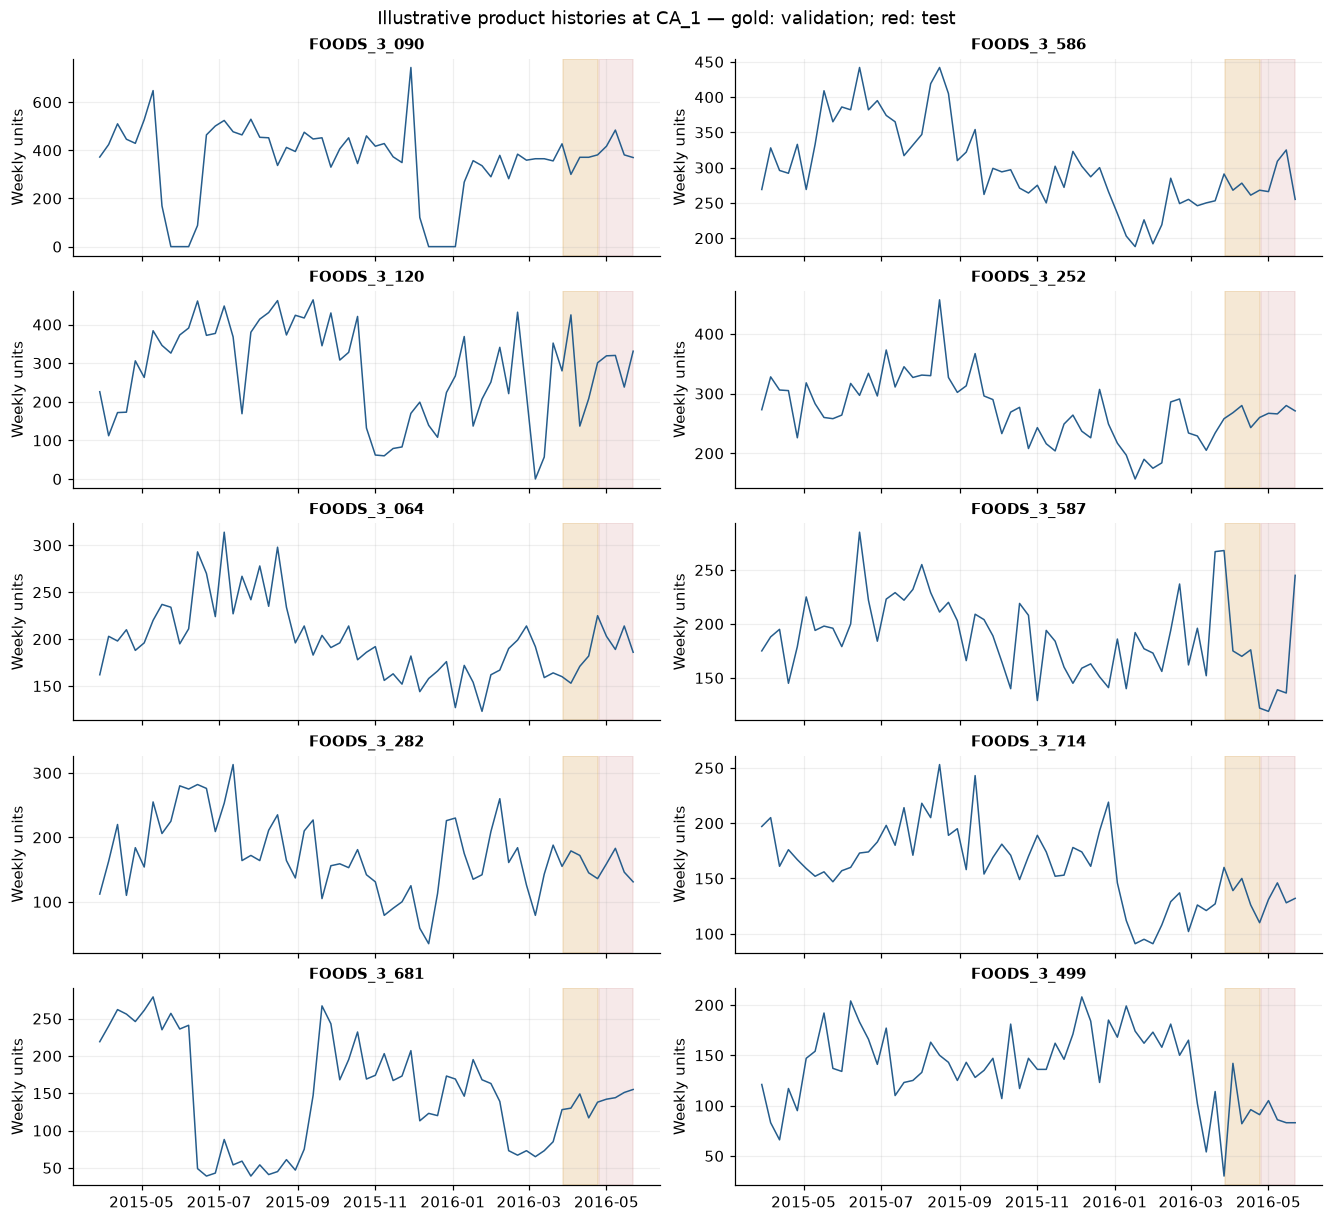

In [15]:
fig,axes=plt.subplots(5,2,figsize=(12,11),sharex=True,layout="constrained")
for axis,item in zip(axes.ravel(),selected.item_id.astype(str)):
    part=selected_daily[selected_daily.item_id.eq(item)].set_index("date").units.resample("W-SUN").sum()
    part=part[part.index >= train_end-pd.Timedelta(days=365)]
    axis.plot(part.index,part,color=BLUE,lw=1)
    axis.axvspan(train_end+pd.Timedelta(days=1),validation_end,color=GOLD,alpha=0.2)
    axis.axvspan(validation_end+pd.Timedelta(days=1),test_end,color=RED,alpha=0.12)
    axis.set_title(item,fontsize=10)
    axis.set_ylabel("Weekly units")
fig.suptitle(f"Illustrative product histories at {EXAMPLE_STORE} — gold: validation; red: test",fontsize=12)
save_figure(fig,"07_selected_product_histories")

## 9 Prediction target, features, and chronological splits

### What is the target?

For a forecast made at the end of Sunday, the target is **total observed units sold
for one product at one store during the next Monday–Sunday week**. Sales are a proxy
for demand because unfilled orders and stockouts are unobserved. We retain complete
seven-day weeks only; the opening two-day partial week is excluded.

This seven-day class-project target differs from the original Kaggle competition's
28-day forecast horizon. Inventory receives the weekly forecast and an assumed price.
Routes and inventory allocations are optimization decisions, not supervised labels.

### Which inputs are available when the forecast is made?

| Input | How constructed | Availability |
|---|---|---|
| Product and store context | Product, department, category, store, state | Known identifiers |
| Last 1, 2, and 4 weeks of sales | Shift weekly observations back from the target week | Historical |
| Trailing 4- and 8-week averages; 4-week variability | Shift first, then calculate rolling statistics | Historical |
| Most recently available selling price | Latest recorded price from a completed Walmart retail week | Assume a weekly average becomes available when that retail week ends |
| Age of the available price | Days between the completed price week and forecast origin | Historical |
| Target week's calendar month and events | Calendar for the next seven days | Assumed known from the supplied calendar |
| Target week's state-specific SNAP day count | Sum the correct state's flag over the next seven days | Known calendar |

Actual target-week sales and actual target-week prices are not model inputs.
Because prices are weekly averages and publication timestamps are not supplied, we
conservatively treat each average as available only when its retail week has ended.
We carry that historical price forward as an assumption; we do not use an average
from a retail week that is still in progress. The price date is retained for audit.

The supplied calendar is treated as available for the target week. For operational
use, events must have been announced by the forecast date; realized sports-event
dates, for example, may need to be excluded or replaced by a planned schedule.
M5 does not provide event-publication timestamps.

In [16]:
group_columns=["store_id","item_id","dept_id","cat_id","state_id"]
weekly=(selected_daily.set_index("date")
        .groupby(group_columns,observed=True)
        .resample("W-SUN")
        .agg(target_units=("units","sum"),observed_days=("d","size"),
             snap_days=("snap_flag","sum"),event_days=("has_event","sum"),
             last_price_in_week=("sell_price","last"),
             price_close=("sell_price",lambda s:s.iloc[-1])))
weekly=weekly.reset_index().rename(columns={"date":"week_end"})
weekly=weekly[weekly.observed_days.eq(7)].sort_values(["store_id","item_id","week_end"]).reset_index(drop=True)
weekly["week_start"]=weekly.week_end-pd.Timedelta(days=6)
weekly["forecast_origin"]=weekly.week_start-pd.Timedelta(days=1)
weekly["target_month"]=weekly.week_start.dt.month
weekly["target_year"]=weekly.week_start.dt.year
groups=weekly.groupby(["store_id","item_id"],observed=True)
for lag in [1,2,4]:
    weekly[f"sales_lag_{lag}w"]=groups.target_units.shift(lag)
for window in [4,8]:
    weekly[f"sales_mean_{window}w"]=groups.target_units.transform(lambda s:s.shift(1).rolling(window,min_periods=window).mean())
weekly["sales_std_4w"]=groups.target_units.transform(lambda s:s.shift(1).rolling(4,min_periods=4).std())
retail_week_dates=calendar.groupby("wm_yr_wk").agg(
    price_information_date=("date","max"),calendar_days=("date","size")).reset_index()
retail_week_dates=retail_week_dates[retail_week_dates.calendar_days.eq(7)]
selected_price_history=prices[(prices.store_id.eq(EXAMPLE_STORE)) & prices.item_id.isin(selected.item_id)]
selected_price_history=selected_price_history.merge(retail_week_dates,on="wm_yr_wk",validate="many_to_one")
weekly["last_observed_price"]=np.nan
weekly["price_information_date"]=pd.NaT
for (store,item),part in weekly.groupby(["store_id","item_id"],observed=True):
    history=selected_price_history[(selected_price_history.store_id.eq(store)) &
                                    selected_price_history.item_id.eq(item)].sort_values("price_information_date")
    known=pd.merge_asof(part[["forecast_origin"]].sort_values("forecast_origin"),
                        history[["price_information_date","sell_price"]],
                        left_on="forecast_origin",right_on="price_information_date",direction="backward")
    weekly.loc[part.index,"last_observed_price"]=known.sell_price.to_numpy()
    weekly.loc[part.index,"price_information_date"]=known.price_information_date.to_numpy()
weekly["price_age_days"]=(weekly.forecast_origin-weekly.price_information_date).dt.days

numeric_features=["sales_lag_1w","sales_lag_2w","sales_lag_4w","sales_mean_4w","sales_mean_8w", "sales_std_4w",
                  "last_observed_price","price_age_days","snap_days","event_days","target_month","target_year"]
categorical_features=["item_id","dept_id","cat_id","store_id","state_id"]
feature_columns=categorical_features+numeric_features
model_panel=weekly.dropna(subset=numeric_features).copy()
model_panel["split"]=np.select([model_panel.week_end.le(train_end),model_panel.week_end.le(validation_end)],
                                ["train","validation"],default="test")
assert not model_panel.duplicated(["store_id","item_id","week_end"]).any()
assert model_panel.forecast_origin.add(pd.Timedelta(days=7)).eq(model_panel.week_end).all()
assert model_panel.price_information_date.le(model_panel.forecast_origin).all()
assert model_panel.groupby(["store_id","item_id"],observed=True).week_end.diff().dropna().eq(pd.Timedelta(days=7)).all()
assert "target_units" not in feature_columns and "price_close" not in feature_columns
assert model_panel.target_units.ge(0).all()
assert model_panel.loc[model_panel.split.eq("train"),"week_end"].max() <= train_end
assert model_panel.loc[model_panel.split.eq("validation"),"week_start"].min() > train_end
assert model_panel.loc[model_panel.split.eq("validation"),"week_end"].max() <= validation_end
assert model_panel.loc[model_panel.split.eq("test"),"week_start"].min() > validation_end

split_summary=model_panel.groupby("split",sort=False).agg(
    product_weeks=("target_units","size"),products=("item_id","nunique"),
    first_target_day=("week_start","min"),last_target_day=("week_end","max"),
    first_forecast_origin=("forecast_origin","min"),last_forecast_origin=("forecast_origin","max")).reset_index()
show_table(split_summary,"forecasting_split_summary")
display(model_panel[["item_id","forecast_origin","week_start","week_end","sales_lag_1w",
                     "sales_mean_4w","last_observed_price","snap_days","target_units","split"]].tail(8))
model_panel[["forecast_origin","week_start","week_end","price_information_date","split"]+feature_columns+["target_units"]].to_csv(
    OUTPUT_DIR/"weekly_forecasting_panel.csv",index=False)
feature_roles=pd.DataFrame({"field":feature_columns+["target_units"],
                           "role":["Categorical input"]*len(categorical_features)+["Numeric input"]*len(numeric_features)+["Observed next-week label"]})
show_table(feature_roles,"forecasting_feature_roles")

,split,product_weeks,products,first_target_day,last_target_day,first_forecast_origin,last_forecast_origin
0,train,2318,10,2011-03-28,2016-03-27,2011-03-27,2016-03-20
1,validation,40,10,2016-03-28,2016-04-24,2016-03-27,2016-04-17
2,test,40,10,2016-04-25,2016-05-22,2016-04-24,2016-05-15


,item_id,forecast_origin,week_start,week_end,sales_lag_1w,sales_mean_4w,last_observed_price,snap_days,target_units,split
2762,FOODS_3_714,2016-03-27,2016-03-28,2016-04-03,160.000,133.500,1.580,3,139,validation
2763,FOODS_3_714,2016-04-03,2016-04-04,2016-04-10,139.000,136.750,1.580,7,150,validation
2764,FOODS_3_714,2016-04-10,2016-04-11,2016-04-17,150.000,144.000,1.580,0,126,validation
2765,FOODS_3_714,2016-04-17,2016-04-18,2016-04-24,126.000,143.750,1.580,0,110,validation
2766,FOODS_3_714,2016-04-24,2016-04-25,2016-05-01,110.000,131.250,1.580,1,131,test
2767,FOODS_3_714,2016-05-01,2016-05-02,2016-05-08,131.000,129.250,1.580,7,146,test
2768,FOODS_3_714,2016-05-08,2016-05-09,2016-05-15,146.000,128.250,1.580,2,128,test
2769,FOODS_3_714,2016-05-15,2016-05-16,2016-05-22,128.000,128.750,1.580,0,132,test


,field,role
0,item_id,Categorical input
1,dept_id,Categorical input
2,cat_id,Categorical input
3,store_id,Categorical input
4,state_id,Categorical input
5,sales_lag_1w,Numeric input
6,sales_lag_2w,Numeric input
7,sales_lag_4w,Numeric input
8,sales_mean_4w,Numeric input
9,sales_mean_8w,Numeric input


### Verify that features stop at the forecast date

For one validation example, the code below independently recomputes the previous
week's units and trailing four-week mean from daily records **on or before the
forecast origin**. It also independently recomputes the next seven-day label.
These checks target the timing errors that commonly invalidate forecasting results.

In [17]:
example=model_panel[model_panel.split.eq("validation")].iloc[0]
example_history=selected_daily[(selected_daily.item_id.eq(example.item_id)) &
                               (selected_daily.store_id.eq(example.store_id))].set_index("date")
origin=example.forecast_origin
last_week_units=example_history.loc[origin-pd.Timedelta(days=6):origin,"units"].sum()
trailing_4week_mean=example_history.loc[origin-pd.Timedelta(days=27):origin,"units"].sum()/4
next_week_units=example_history.loc[origin+pd.Timedelta(days=1):origin+pd.Timedelta(days=7),"units"].sum()
completed_prices=selected_price_history[(selected_price_history.item_id.eq(example.item_id)) &
                                       (selected_price_history.store_id.eq(example.store_id)) &
                                       selected_price_history.price_information_date.le(origin)]
last_available_price=completed_prices.sort_values("price_information_date").sell_price.iloc[-1]
assert last_week_units == example.sales_lag_1w
assert np.isclose(trailing_4week_mean,example.sales_mean_4w)
assert next_week_units == example.target_units
assert np.isclose(last_available_price,example.last_observed_price)
assert example.price_information_date <= origin
display(pd.DataFrame({"check":["Previous week sales","Trailing four-week mean","Historical price at origin","Next-week label"],
                      "independent_value":[last_week_units,trailing_4week_mean,last_available_price,next_week_units],
                      "panel_value":[example.sales_lag_1w,example.sales_mean_4w,example.last_observed_price,example.target_units]}))

,check,independent_value,panel_value
0,Previous week sales,160.000,160.000
1,Trailing four-week mean,168.750,168.750
2,Historical price at origin,1.180,1.180
3,Next-week label,153.000,153.000


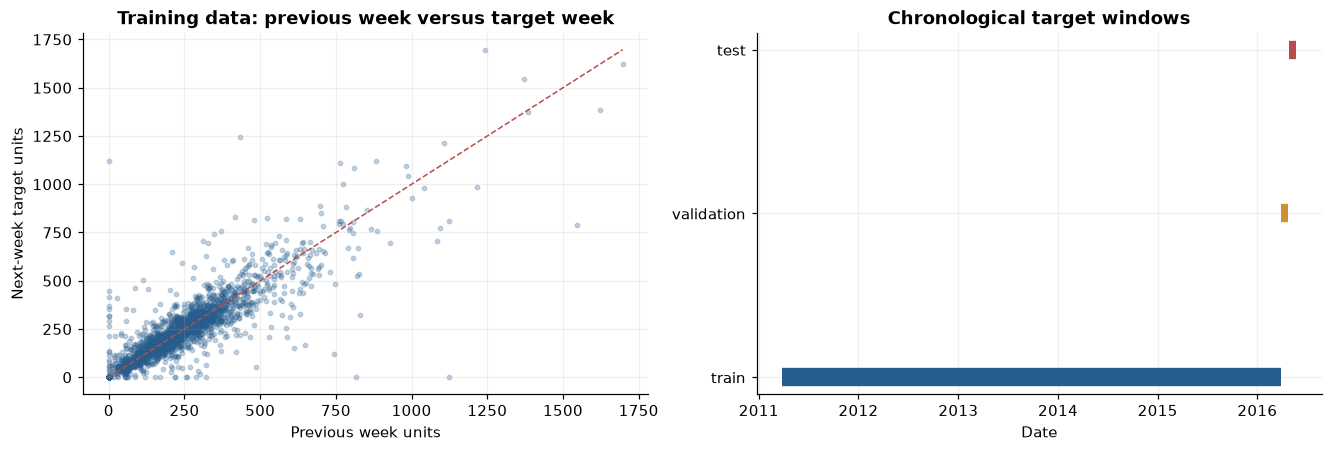

In [18]:
fig,ax=plt.subplots(1,2,figsize=(12,4),layout="constrained")
training=model_panel[model_panel.split.eq("train")]
ax[0].scatter(training.sales_lag_1w,training.target_units,s=8,color=BLUE,alpha=0.25)
max_units=max(training.sales_lag_1w.max(),training.target_units.max())
ax[0].plot([0,max_units],[0,max_units],color=RED,lw=1,ls="--")
ax[0].set(title="Training data: previous week versus target week",xlabel="Previous week units",ylabel="Next-week target units")
for split,color in [("train",BLUE),("validation",GOLD),("test",RED)]:
    part=model_panel[model_panel.split.eq(split)]
    ax[1].plot([part.week_start.min(),part.week_end.max()],[split,split],lw=12,color=color,solid_capstyle="butt")
ax[1].set(title="Chronological target windows",xlabel="Date")
save_figure(fig,"08_forecasting_inputs_and_splits")

## 10 Simple validation baselines

These small baselines illustrate whether the target and feature table are usable;
they do not constitute the team's final forecasting model. We evaluate **validation
weeks only**. Each forecast is made one week ahead using sales available at that
week's origin, including earlier validation weeks after they have actually occurred.
This is rolling-origin evaluation, not a four-week forecast made all at once.

- **Previous week:** repeat the previous week's total.
- **Trailing four-week mean:** predict the mean of the preceding four weekly totals.

MAE and RMSE are measured in units per product-week. WAPE divides total absolute
error by total actual units and is omitted if that denominator is zero. These are
class-project diagnostics, not the official Kaggle competition scoring procedure.
We leave the test window unevaluated for a later model comparison.

In [19]:
validation=model_panel[model_panel.split.eq("validation")].copy()
baseline_records=[]
for name,column in [("Previous week","sales_lag_1w"),("Trailing 4-week mean","sales_mean_4w")]:
    error=validation[column].to_numpy()-validation.target_units.to_numpy()
    denominator=float(validation.target_units.sum())
    baseline_records.append({"baseline":name,"validation_product_weeks":len(validation),
                             "MAE_units":float(np.mean(np.abs(error))),"RMSE_units":float(np.sqrt(np.mean(error**2))),
                             "WAPE":float(np.sum(np.abs(error))/denominator) if denominator>0 else np.nan})
baseline_results=pd.DataFrame(baseline_records)
show_table(baseline_results,"validation_baselines")
display(Markdown("Baseline scores describe this selected subset only. Final model decisions should also assess "
                 "uncertainty and performance by product; a good aggregate score can hide weak performance for individual items."))

,baseline,validation_product_weeks,MAE_units,RMSE_units,WAPE
0,Previous week,40,39.475,66.481,0.195
1,Trailing 4-week mean,40,35.712,57.576,0.176


Baseline scores describe this selected subset only. Final model decisions should also assess uncertainty and performance by product; a good aggregate score can hide weak performance for individual items.

## 11 Inventory and routing implications

| Stage | What M5 supplies | What must be defined or assumed |
|---|---|---|
| Forecasting | Observed product–store unit sales, calendar context, listed prices | Horizon, feature availability, evaluation split, model and uncertainty method |
| Inventory | Weekly demand forecasts derived from sales and selling prices | The assignment's ten products and 100-unit capacity; replenishment timing; stock availability; cost assumptions if modeling costs |
| Routing | Store identifiers and shipment quantities derived from allocation | Depot and destination coordinates, distance matrix or road network, vehicle capacities, costs and emissions factors |

**Inventory:** a selling price supports revenue calculations, but it does not reveal
profit. M5 does not provide purchasing, holding, shortage, or replenishment costs.
The 100-unit capacity comes from the assignment, not the dataset. If total forecast
demand is below 100, a model that both requires exactly 100 units and forbids stocking
above forecast demand may be infeasible; capacity and allocation rules need explicit interpretation.

**Routing:** we could define a small warehouse-to-store scenario using documented
simulated locations and vehicle assumptions. Store codes such as `CA_1` are not exact
addresses. A single-store inventory example is not, by itself, a multi-stop delivery
problem; the later routing scenario needs additional destinations or stores and their
own shipment quantities. Synthetic geography must be labeled separately from M5 observations.

**Demand interpretation:** sales can be limited by stockouts and other constraints.
No inventory ledger or lost-sales labels are provided, so observed sales cannot be
assumed to equal unconstrained demand.

**Canadian application:** the data can support methods development, but U.S. SNAP
flags and U.S. prices should not be presented as Canadian operating conditions.
A Canadian deployment would need relevant local data and calendar features.

## 12 Data Understanding draft and exports

The next cell creates a concise report draft using the values calculated above.
It keeps observed facts separate from proposed project choices. The notebook's
earlier sections provide the detailed evidence and reproducible calculations.

In [20]:
report_text = f"""# Data Understanding

**Group 2 - MIA5130A Systems Optimization and Management**

We propose M5 Forecasting — Accuracy as the main dataset for the supply chain project. It contains daily Walmart unit sales for {sales.item_id.nunique():,} anonymized products across {sales.store_id.nunique()} stores in California, Texas, and Wisconsin, organized into {sales.cat_id.nunique()} categories and {sales.dept_id.nunique()} departments. The dataset is available through [Kaggle](https://www.kaggle.com/competitions/m5-forecasting-accuracy/data).

## Files and structure

The main sales file, sales_train_evaluation.csv, contains {len(sales):,} product–store rows and {len(day_cols):,} daily sales columns, covering {dates.min().date()} to {dates.max().date()}. calendar.csv contains {len(calendar):,} daily records with dates, retail-week identifiers, events, and state-specific SNAP flags. sell_prices.csv contains {len(prices):,} product–store–week price records. Calendar data joins on d, while prices join on item_id, store_id, and wm_yr_wk. The shorter sales_train_validation.csv duplicates the overlapping {len(validation_days):,} days and should not be appended. sample_submission.csv is a competition output template.

SNAP means Supplemental Nutrition Assistance Program, a U.S. government program that helps eligible low-income households buy food. In M5, snap_CA, snap_TX, and snap_WI mark SNAP purchasing days for the corresponding state: 1 indicates a flagged date and 0 an unflagged date. These fields describe the U.S. retail context, even though our team is based in Canada. See [USDA](https://www.ers.usda.gov/topics/food-nutrition-assistance/supplemental-nutrition-assistance-program-snap) for the program definition.

## Inputs and target

We could define the target as total observed units sold for each product and store during the next Monday–Sunday week, matching the inventory milestone's weekly decision. Candidate inputs include product and location identifiers, lagged sales, trailing sales averages, calendar events, the matching state's SNAP flag, and prices known at the forecast origin. Future observed prices must not be treated as known inputs unless supplied as a declared price plan. Holding the last observed price constant is an explicit assumption.

## Initial data quality findings

The longer sales file contains {observation_count:,} daily observations, with {sales_nulls} missing sales cells, {negative_sales} negative counts, and {sales_duplicates} duplicate product–store keys. Zero sales account for {zero_fraction:.1%} of observations. Calendar dates are consecutive and cover all observed sales days. Optional event fields are blank when no event is listed. The price file has no missing cell values or duplicate product–store–week keys, but {missing_price_fraction:.1%} of historical product–store-days have no matching price record; all have zero sales. Within days with a listed price, {priced_zero_fraction:.1%} of sales observations are zero. These distinctions matter for handling selling-history coverage and sparse demand.

## Preparation and proposed scope

We could use ten food products at {EXAMPLE_STORE} for the assignment's 100-unit inventory scenario. The illustrative subset in this notebook uses only training-period coverage and volume; the team still needs to agree on the final products and routing scope. Sales will be reshaped for the selected subset, joined to calendar and price data, and aggregated into complete seven-day targets. Training, validation, and test targets follow time order. The illustrative training cutoff is {train_end.date()}, followed by 28 validation days and 28 test days. Lag and rolling features use only observations available at each forecast origin.

## Limits for inventory and routing

Observed sales are a proxy for demand because stockouts and unmet demand are not measured. Selling prices support revenue calculations but not profit without cost assumptions. Inventory allocations and routes are optimization outputs, not supervised labels. M5 provides store codes but no exact coordinates, depot, road network, vehicle capacities, or emissions factors. We could define a documented simulated routing network with multiple destinations and clearly distinguish those assumptions from observed M5 data. The dataset's U.S. prices and SNAP context would require adaptation for a Canadian operational setting.
"""
(OUTPUT_DIR/"data_understanding.md").write_text(report_text,encoding="utf-8")
display(Markdown(report_text))

# Data Understanding

**Group 2 - MIA5130A Systems Optimization and Management**

We propose M5 Forecasting — Accuracy as the main dataset for the supply chain project. It contains daily Walmart unit sales for 3,049 anonymized products across 10 stores in California, Texas, and Wisconsin, organized into 3 categories and 7 departments. The dataset is available through [Kaggle](https://www.kaggle.com/competitions/m5-forecasting-accuracy/data).

## Files and structure

The main sales file, sales_train_evaluation.csv, contains 30,490 product–store rows and 1,941 daily sales columns, covering 2011-01-29 to 2016-05-22. calendar.csv contains 1,969 daily records with dates, retail-week identifiers, events, and state-specific SNAP flags. sell_prices.csv contains 6,841,121 product–store–week price records. Calendar data joins on d, while prices join on item_id, store_id, and wm_yr_wk. The shorter sales_train_validation.csv duplicates the overlapping 1,913 days and should not be appended. sample_submission.csv is a competition output template.

SNAP means Supplemental Nutrition Assistance Program, a U.S. government program that helps eligible low-income households buy food. In M5, snap_CA, snap_TX, and snap_WI mark SNAP purchasing days for the corresponding state: 1 indicates a flagged date and 0 an unflagged date. These fields describe the U.S. retail context, even though our team is based in Canada. See [USDA](https://www.ers.usda.gov/topics/food-nutrition-assistance/supplemental-nutrition-assistance-program-snap) for the program definition.

## Inputs and target

We could define the target as total observed units sold for each product and store during the next Monday–Sunday week, matching the inventory milestone's weekly decision. Candidate inputs include product and location identifiers, lagged sales, trailing sales averages, calendar events, the matching state's SNAP flag, and prices known at the forecast origin. Future observed prices must not be treated as known inputs unless supplied as a declared price plan. Holding the last observed price constant is an explicit assumption.

## Initial data quality findings

The longer sales file contains 59,181,090 daily observations, with 0 missing sales cells, 0 negative counts, and 0 duplicate product–store keys. Zero sales account for 68.0% of observations. Calendar dates are consecutive and cover all observed sales days. Optional event fields are blank when no event is listed. The price file has no missing cell values or duplicate product–store–week keys, but 20.8% of historical product–store-days have no matching price record; all have zero sales. Within days with a listed price, 59.6% of sales observations are zero. These distinctions matter for handling selling-history coverage and sparse demand.

## Preparation and proposed scope

We could use ten food products at CA_1 for the assignment's 100-unit inventory scenario. The illustrative subset in this notebook uses only training-period coverage and volume; the team still needs to agree on the final products and routing scope. Sales will be reshaped for the selected subset, joined to calendar and price data, and aggregated into complete seven-day targets. Training, validation, and test targets follow time order. The illustrative training cutoff is 2016-03-27, followed by 28 validation days and 28 test days. Lag and rolling features use only observations available at each forecast origin.

## Limits for inventory and routing

Observed sales are a proxy for demand because stockouts and unmet demand are not measured. Selling prices support revenue calculations but not profit without cost assumptions. Inventory allocations and routes are optimization outputs, not supervised labels. M5 provides store codes but no exact coordinates, depot, road network, vehicle capacities, or emissions factors. We could define a documented simulated routing network with multiple destinations and clearly distinguish those assumptions from observed M5 data. The dataset's U.S. prices and SNAP context would require adaptation for a Canadian operational setting.


In [21]:
profile={
    "dataset_source":"https://www.kaggle.com/competitions/m5-forecasting-accuracy/data",
    "files":file_structure.to_dict(orient="records"),
    "observed_sales_dates":{"start":str(dates.min().date()),"end":str(dates.max().date())},
    "sales":{"series":len(sales),"days":len(day_cols),"daily_observations":observation_count,
             "zero_fraction":zero_fraction,"zero_fraction_with_listed_price":priced_zero_fraction,
             "missing_cells":sales_nulls,"negative_counts":negative_sales,"duplicate_item_store_keys":sales_duplicates},
    "prices":{"rows":len(prices),"minimum_USD":float(prices.sell_price.min()),"maximum_USD":float(prices.sell_price.max()),
              "missing_historical_join_days":missing_price_days,"missing_historical_join_fraction":missing_price_fraction,
              "missing_days_before_first_recorded_price_week":missing_before_first_price,
              "positive_sales_without_price":positive_without_price,"duplicate_keys":price_duplicates},
    "overlap":{"same_sales":bool(same_sales),"same_ids":bool(same_keys),"same_metadata":bool(same_metadata)},
    "illustrative_scope":{"store":EXAMPLE_STORE,"category":EXAMPLE_CATEGORY,"products":selected.item_id.astype(str).tolist(),
                          "selection_uses_training_only":True,"train_end":str(train_end.date()),
                          "validation_end":str(validation_end.date()),"test_end":str(test_end.date())},
    "quality_checks_all_passed":bool(quality.passed.all()),"versions":versions,
    "source_md5":source_hashes,
}
(OUTPUT_DIR/"data_profile.json").write_text(json.dumps(profile,indent=2,default=str),encoding="utf-8")
(OUTPUT_DIR/"environment_versions.json").write_text(json.dumps(versions,indent=2),encoding="utf-8")

# Confirm that analysis did not alter any of the source CSV files.
for filename,original_hash in source_hashes.items():
    assert file_md5(DATA_DIR/filename)==original_hash, f"Source file changed: {filename}"
outputs=pd.DataFrame([{"file":str(p.relative_to(OUTPUT_DIR)),"size_KiB":p.stat().st_size/1024}
                      for p in sorted(OUTPUT_DIR.rglob("*")) if p.is_file()])
display(outputs)
display(Markdown("**Completed:** source files remained unchanged; all structural checks passed; "
                 "the selected daily table and weekly forecasting panel were exported. "
                 "Final team choices remain the product/store scope, forecast uncertainty approach, and routing assumptions."))

,file,size_KiB
0,category_totals.csv,0.127
1,daily_totals.csv,132.679
2,data_dictionary.csv,1.422
3,data_profile.json,2.803
4,data_understanding.md,3.963
5,dates_with_zero_total_sales.csv,0.052
6,environment_versions.json,0.137
7,figures/01_category_and_store_sales.png,47.894
8,figures/02_sales_distribution.png,62.475
9,figures/03_total_sales_and_coverage.png,297.725


**Completed:** source files remained unchanged; all structural checks passed; the selected daily table and weekly forecasting panel were exported. Final team choices remain the product/store scope, forecast uncertainty approach, and routing assumptions.

## Sources and methodological notes

1. Howard, A., inversion, Makridakis, S., and vangelis. (2020).
   [M5 Forecasting — Accuracy](https://www.kaggle.com/competitions/m5-forecasting-accuracy/data). Kaggle.
   Source of the five supplied CSV files and dataset field definitions.
2. U.S. Department of Agriculture, Economic Research Service.
   [Supplemental Nutrition Assistance Program (SNAP)](https://www.ers.usda.gov/topics/food-nutrition-assistance/supplemental-nutrition-assistance-program-snap).
   Used to explain the U.S. food assistance program for Canadian readers.

All numerical findings are computed locally from the supplied files. The ten-product
scope, weekly aggregation, temporal split, baseline comparisons, and proposed routing
assumptions are project choices, not claims made by the dataset publisher.